# Hard Thresholding final convergence run on Fritz

Run the selected rank 12 for 450 iterations and retain the iteration with the lowest validation RMSE.

In [1]:
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from hard_thresholding_hpc import (
    hard_thresholding_model_matrix_free,
    predict_pairs,
)

In [2]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "ml-latest"
RESULTS_DIR = PROJECT_ROOT / "results" / "hard_thresholding_final_convergence"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(PROCESSED_DIR / "train_ratings.csv")
user_map = pd.read_csv(PROCESSED_DIR / "user_map.csv")
movie_map = pd.read_csv(PROCESSED_DIR / "movie_map.csv")

n_users = len(user_map)
n_movies = len(movie_map)

train_fit_df, val_df = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42,
    shuffle=True,
)

val_user_idx = val_df["user_idx"].to_numpy(dtype=np.int64)
val_movie_idx = val_df["movie_idx"].to_numpy(dtype=np.int64)
val_ratings = val_df["rating"].to_numpy(dtype=np.float64)

print("Train fit shape:", train_fit_df.shape)
print("Validation shape:", val_df.shape)
print("Number of users:", n_users)
print("Number of movies:", n_movies)

Train fit shape: (21652583, 6)
Validation shape: (5413146, 6)
Number of users: 330975
Number of movies: 83239


In [3]:
def validation_metrics(U, singular_values, V):
    predictions = predict_pairs(
        U,
        singular_values,
        V,
        val_user_idx,
        val_movie_idx,
    )
    predictions = np.clip(predictions, 0.5, 5.0)
    return {
        "val_rmse": float(np.sqrt(np.mean((val_ratings - predictions) ** 2))),
    }

In [4]:
rank = 12
max_iter = 450
svd_tol = 1e-4
svd_maxiter = 300
history_path = RESULTS_DIR / "history.csv"

# Compile the Numba prediction kernel before timing the model.
predict_pairs(
    np.ones((2, 1)),
    np.ones(1),
    np.ones((2, 1)),
    np.array([0], dtype=np.int64),
    np.array([0], dtype=np.int64),
)

if history_path.exists():
    print("Using saved history.")
    history = pd.read_csv(history_path)
else:
    start = perf_counter()
    _, _, _, history = hard_thresholding_model_matrix_free(
        train_fit_df,
        n_users=n_users,
        n_movies=n_movies,
        rank=rank,
        n_iter=max_iter,
        metrics_fn=validation_metrics,
        svd_tol=svd_tol,
        svd_maxiter=svd_maxiter,
        random_state=42,
    )
    history["run_seconds"] = perf_counter() - start
    history.to_csv(history_path, index=False)

print(f"Completed iterations: {len(history)}")

Completed iterations: 450


In [5]:
best_row = history.loc[history["val_rmse"].idxmin()]
best_iteration = int(best_row["iteration"])
best_val_rmse = float(best_row["val_rmse"])

rmse_at_400 = float(
    history.loc[history["iteration"] == 400, "val_rmse"].iloc[0]
)
rmse_at_450 = float(
    history.loc[history["iteration"] == 450, "val_rmse"].iloc[0]
)
last_50_improvement = rmse_at_400 - rmse_at_450

best_parameters = pd.DataFrame([{
    "rank": rank,
    "n_iter": best_iteration,
    "val_rmse": best_val_rmse,
    "last_50_improvement": last_50_improvement,
}])
best_parameters.to_csv(RESULTS_DIR / "best_parameters.csv", index=False)
display(best_parameters)

display(
    history.loc[
        history["iteration"].isin([350, 400, 420, 430, 440, 450]),
        ["iteration", "train_rmse", "val_rmse"],
    ]
)

if best_iteration == max_iter:
    print("Best iteration is the last one.")
else:
    print("Best iteration is inside the trajectory.")

,rank,n_iter,val_rmse,last_50_improvement
0,12,450,0.809475,0.000151


,iteration,train_rmse,val_rmse
349,350,0.716026,0.809900
399,400,0.713416,0.809626
419,420,0.712495,0.809554
429,430,0.712056,0.809524
439,440,0.711632,0.809498
449,450,0.711220,0.809475


Best iteration is the last one.


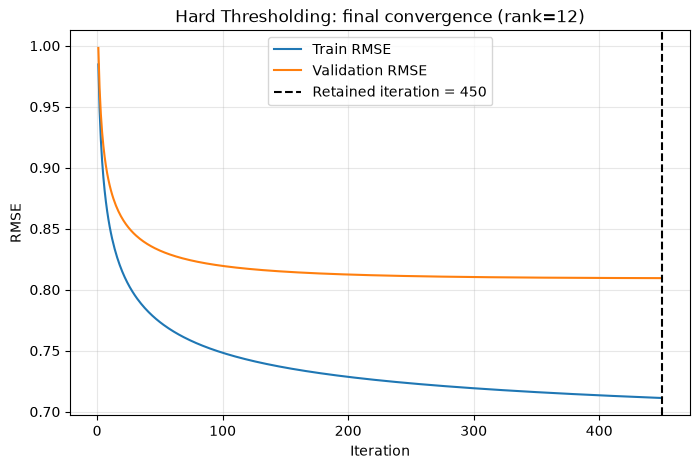

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(history["iteration"], history["train_rmse"], label="Train RMSE")
plt.plot(history["iteration"], history["val_rmse"], label="Validation RMSE")
plt.axvline(
    best_iteration,
    linestyle="--",
    color="black",
    label=f"Retained iteration = {best_iteration}",
)
plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title("Hard Thresholding: final convergence (rank=12)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()